Clase 011 · `011_matplotlib2` · El año promedio de la libreta anterior reacomodado como
una matriz de 24 horas × 366 días con `pivot`, y dibujado con `imshow`: un mapa de calor
que muestra de un vistazo a qué horas y en qué meses hace más calor.

::: {.callout-important title="Datos"}
`anio_promedio-2020-2026.parquet` lo produce la libreta `003_AnioPromedio` en
`clases/011_matplotlib2/data/003_results/`; córrela primero.
:::

## Librerías

`pandas` y `matplotlib`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## Leer el año promedio

8784 filas horarias de 2024, diez variables, sin faltantes.

In [2]:
f = "../data/003_results/anio_promedio-2020-2026.parquet"
esolmet = pd.read_parquet(f)
esolmet.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 8784 entries, 2024-01-01 00:00:00 to 2024-12-31 23:00:00
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   dhi       8784 non-null   float64
 1   dni       8784 non-null   float64
 2   ghi       8784 non-null   float64
 3   p_atm     8784 non-null   float64
 4   rain_acc  8784 non-null   float64
 5   rh        8784 non-null   float64
 6   tdb       8784 non-null   float64
 7   uv        8784 non-null   float64
 8   wd        8784 non-null   float64
 9   ws        8784 non-null   float64
dtypes: float64(10)
memory usage: 754.9 KB


## Quedarse con la temperatura como `DataFrame`

`esolmet.tdb` es una `Series`; `pd.DataFrame(...)` la convierte en un `DataFrame` de una
columna porque `pivot` trabaja sobre `DataFrame`s y porque le vamos a agregar columnas.

In [3]:
tdb = pd.DataFrame(esolmet.tdb)
tdb

,tdb
date,
2024-01-01 00:00:00,17.836633
2024-01-01 01:00:00,16.722500
2024-01-01 02:00:00,16.212367
2024-01-01 03:00:00,15.727033
2024-01-01 04:00:00,15.100200
...,...
2024-12-31 19:00:00,21.350900
2024-12-31 20:00:00,20.198333
2024-12-31 21:00:00,19.806367


La única columna, `tdb`.

In [4]:
tdb.columns

Index(['tdb'], dtype='str')

El mismo `DataFrame`, para tenerlo a la vista antes de transformarlo.

In [5]:
tdb

,tdb
date,
2024-01-01 00:00:00,17.836633
2024-01-01 01:00:00,16.722500
2024-01-01 02:00:00,16.212367
2024-01-01 03:00:00,15.727033
2024-01-01 04:00:00,15.100200
...,...
2024-12-31 19:00:00,21.350900
2024-12-31 20:00:00,20.198333
2024-12-31 21:00:00,19.806367


## Dos columnas auxiliares y `pivot`

Sacamos del índice la hora (`index.hour`) y la fecha sin año (`strftime("%m-%d")`) como
dos columnas nuevas. `pd.pivot` reacomoda la tabla: `index="hora"` pone una fila por hora,
`columns="mes-dia"` una columna por día del año y `values="tdb"` llena cada celda con la
temperatura. De una columna larga de 8784 valores pasamos a una matriz de 24 × 366. Las
líneas comentadas son las inspecciones que se hicieron en clase.

In [6]:
tdb["hora"] = tdb.index.hour
tdb["mes-dia"] = tdb.index.strftime("%m-%d")
# tdb
tdb_matriz = pd.pivot(tdb,index='hora', columns='mes-dia',values="tdb")
# tdb_matriz

## Rango de la variable para la escala de color

Necesitamos el mínimo y el máximo de la temperatura para fijar la escala del heatmap:
14.1 y 36.2 °C. `max()` y `min()` responden por cada columna, por eso también aparecen
`hora` y `mes-dia`.

In [7]:
tdb.max(),tdb.min()

(tdb        36.194333
 hora              23
 mes-dia        12-31
 dtype: object,
 tdb        14.069333
 hora               0
 mes-dia        01-01
 dtype: object)

## Dibujar con `imshow`

`imshow` pinta una matriz como imagen: cada celda es un pixel coloreado según su valor.
`cmap="jet"` es el mapa de color, `vmin` y `vmax` fijan la escala a 14 y 36 °C y
`aspect=5` estira las celdas a lo ancho para que 366 columnas quepan junto a 24 filas.
`fig.colorbar(mapa)` agrega la barra de referencia.

Lectura: las filas son horas (0 arriba, 23 abajo) y las columnas días del año. La franja
roja entre las filas 12 y 18 son las tardes, y es más intensa entre los días 100 y 150
(abril y mayo), el periodo más caliente del año en Temixco. Las noches, arriba y abajo,
son azules todo el año. Queda pendiente poner horas y meses en los ejes en lugar de los
índices de la matriz.

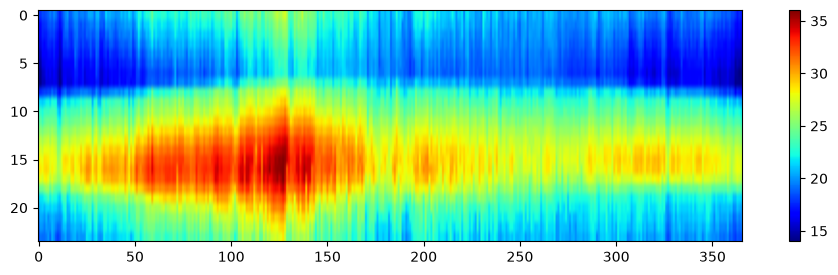

In [8]:
#| label: fig-heatmap-tdb
#| fig-cap: "Heatmap de la temperatura de bulbo seco del año promedio: filas de 0 a 23 horas, columnas de 0 a 365 días, escala de 14 a 36 °C con el mapa `jet`. La franja roja de las tardes es más intensa en abril y mayo."
#| fig-alt: "Imagen rectangular con una franja roja horizontal entre las filas 12 y 18, más intensa hacia las columnas 100 a 150, sobre fondo azul en las filas de la noche; barra de color a la derecha de 15 a 35."
fig, ax = plt.subplots(figsize=(12,3))

mapa = ax.imshow(tdb_matriz,cmap="jet",aspect=5,vmax=36,vmin=14)

fig.colorbar(mapa)



## Dimensiones de la matriz

24 filas (horas) por 366 columnas (días).

In [9]:
len(tdb_matriz),len(tdb_matriz.columns)

(24, 366)

Celda vacía que quedó al final de la clase.